# Laporan Hasil Training & Evaluasi Eksperimen Dataset v3 (RTX 5090)
## Perbandingan Sebelum vs Sesudah Fine-Tuning LoRA serta Perbedaan Model (`Qwen2.5-3B-Instruct` vs `Qwen3-4B-Instruct-2507`)

Notebook ini menyajikan **bukti empiris lengkap** hasil *fine-tuning* QLoRA menggunakan **Dataset v3** (`760 train`, `172 val`, `162 test` — total `1.094` dialog tanpa kebocoran tag/metadata) pada GPU **NVIDIA GeForce RTX 5090 (32 GB VRAM, BF16)**.

### Cakupan Analisis di Notebook Ini:
1. **Bukti Artefak & Kurva Training QLoRA (`run_manifest.json`, `trainer_state.json`, `evaluation.json`)**:
   - Membandingkan proses pelatihan kedua model (`Qwen/Qwen2.5-3B-Instruct` dan `Qwen/Qwen3-4B-Instruct-2507`) dari Step 5 hingga Step 380 (4 Epoch penuh dengan regularisasi `weight_decay=0.05`, `max_grad_norm=1.0`, dan `neftune_noise_alpha=5.0`).
2. **Perbandingan Kuantitatif Sebelum Train (Base Model) vs Sesudah Train (LoRA v3)**:
   - **Held-Out Test Split (`data/lora/lora_test.jsonl`, 162 baris):** Penurunan *Cross-Entropy Loss* dan *Perplexity* ($e^{\text{Loss}}$) sebelum vs sesudah pelatihan pada kedua arsitektur model.
   - **Benchmark 40 Kasus Rubrik 5 Dimensi KKA (`evals/eval_cases.jsonl`):** Lonjakan *Pass Rate* dan skor 5 dimensi (`tuntas`, `akurat`, `proporsional`, `bersih`, `fokus`) dari kondisi *Base Model* (Sebelum Train) $\rightarrow$ *Baseline v2* $\rightarrow$ *LoRA Dataset v3*.
3. **Analisis Perbedaan Model (`Qwen/Qwen2.5-3B-Instruct` vs `Qwen/Qwen3-4B-Instruct-2507`)**:
   - Mengapa `Qwen3-4B-Instruct-2507` mencapai **Pass Rate `40/40 (100,0%)`** dengan `eval_loss = 1.3838`, sedangkan `Qwen2.5-3B-Instruct` mencapai **`30/40 (75,0%)`** dengan `eval_loss = 1.5767`.
   - Bedah kasus-kasus pembeda dan perbandingan jawaban nyata (*side-by-side*) **Sebelum Train vs Sesudah Train (`Qwen2.5-3B` vs `Qwen3-4B`)**.


## 1. Pemeriksaan Bukti Artefak Training Kedua Model (`run_manifest.json` & `evaluation.json`)

Sel berikut memuat dan membandingkan metadata pelatihan, konfigurasi QLoRA, waktu komputasi, serta penurunan *Loss* dan *Perplexity* pada:
- **Eksperimen A:** `adapters/qwen-kka-lora-v3-qwen25` (`Qwen/Qwen2.5-3B-Instruct`)
- **Eksperimen B:** `adapters/qwen-kka-lora-v3-qwen3-4b` (`Qwen/Qwen3-4B-Instruct-2507`)


In [1]:
import json
import math
import sys
from pathlib import Path

PROJECT_ROOT = Path.cwd().resolve()
if PROJECT_ROOT.name == 'notebooks':
    PROJECT_ROOT = PROJECT_ROOT.parent
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

MODELS_EXP = {
    'Qwen2.5-3B-Instruct (v3)': PROJECT_ROOT / 'adapters' / 'qwen-kka-lora-v3-qwen25',
    'Qwen3-4B-Instruct-2507 (v3)': PROJECT_ROOT / 'adapters' / 'qwen-kka-lora-v3-qwen3-4b',
}

artifacts = {}
for label, adir in MODELS_EXP.items():
    manifest = json.loads((adir / 'run_manifest.json').read_text(encoding='utf-8'))
    state = json.loads((adir / 'trainer_state.json').read_text(encoding='utf-8'))
    ev = json.loads((adir / 'evaluation.json').read_text(encoding='utf-8'))
    train_logs = [x for x in state['log_history'] if 'loss' in x]
    eval_logs = [x for x in state['log_history'] if 'eval_loss' in x][:-1]
    summary_log = [x for x in state['log_history'] if 'train_loss' in x][0]
    losses = [x['loss'] for x in train_logs]
    min_entry = min(train_logs, key=lambda x: x['loss'])
    artifacts[label] = {
        'dir': adir,
        'manifest': manifest,
        'state': state,
        'evaluation': ev,
        'train_logs': train_logs,
        'eval_logs': eval_logs,
        'summary_log': summary_log,
        'losses': losses,
        'min_entry': min_entry,
    }

    print('=' * 86)
    print(f'BUKTI ARTEFAK TRAINING LORA — {label.upper()}')
    print('=' * 86)
    print(f"Lokasi Adaptor Final : {adir.relative_to(PROJECT_ROOT)}/final")
    print(f"Best Checkpoint      : {state['best_model_checkpoint']} (Step {state['best_global_step']})")
    print(f"Model Dasar & Revisi : {manifest['model']['model_id']} ({manifest['model']['revision'][:12]}...)")
    print(f"Perangkat GPU        : {manifest['gpu']} (CUDA {manifest['cuda']}, PyTorch {manifest['torch']})")
    print(f"Data Latih & Val     : {manifest['train_rows']} train ({len(manifest['train_groups'])} grup) | {manifest['validation_rows']} val ({len(manifest['validation_groups'])} grup)")
    print(f"Konfigurasi LoRA     : r={manifest['lora']['r']}, alpha={manifest['lora']['lora_alpha']}, dropout={manifest['lora']['lora_dropout']}, modules={manifest['lora']['target_modules']}")
    targs = manifest['training_args']
    print(f"Regularisasi v3      : lr={targs['learning_rate']}, weight_decay={targs['weight_decay']}, max_grad_norm={targs['max_grad_norm']}, neftune={targs.get('neftune_noise_alpha')}")
    print(f"Waktu Pelatihan      : {summary_log['train_runtime']:.1f} detik ({summary_log['train_runtime']/60:.2f} menit) | {state['global_step']} step ({state['epoch']:.1f} epoch)")
    print('-' * 86)
    print(f"- Loss Awal (Step 5)               : {losses[0]:.4f}  (Perplexity: {math.exp(losses[0]):.2f})")
    print(f"- Loss Latih Terendah (Step {min_entry['step']:>3})   : {min_entry['loss']:.4f}  (Perplexity: {math.exp(min_entry['loss']):.2f})")
    print(f"- Rata-Rata Training Loss          : {summary_log['train_loss']:.4f}  (Perplexity: {math.exp(summary_log['train_loss']):.2f})")
    for e_log in eval_logs:
        tag = ' <-- BEST MODEL' if e_log['step'] == state['best_global_step'] else ''
        print(f"- Validation Loss Epoch {e_log['epoch']:.0f} (Step {e_log['step']:>3}): {e_log['eval_loss']:.4f}  (Perplexity: {math.exp(e_log['eval_loss']):.2f}){tag}")
    print(f"- Final Best Eval Loss (Disimpan)  : {ev['eval_loss']:.4f}  (Perplexity: {math.exp(ev['eval_loss']):.2f})")
    print(f"- Penurunan Loss (Awal -> Best)    : -{losses[0] - ev['eval_loss']:.4f} (-{(losses[0] - ev['eval_loss'])/losses[0]*100:.1f}%)")
    print('=' * 86 + '\n')


BUKTI ARTEFAK TRAINING LORA — QWEN2.5-3B-INSTRUCT (V3)
Lokasi Adaptor Final : adapters/qwen-kka-lora-v3-qwen25/final
Best Checkpoint      : adapters/qwen-kka-lora-v3-qwen25/checkpoints/checkpoint-190 (Step 190)
Model Dasar & Revisi : Qwen/Qwen2.5-3B-Instruct (aa8e72537993...)
Perangkat GPU        : NVIDIA GeForce RTX 5090 (CUDA 12.8, PyTorch 2.7.1+cu128)
Data Latih & Val     : 760 train (380 grup) | 172 val (86 grup)
Konfigurasi LoRA     : r=16, alpha=32, dropout=0.1, modules={'q_proj', 'v_proj', 'up_proj', 'k_proj', 'down_proj', 'gate_proj', 'o_proj'}
Regularisasi v3      : lr=0.0001, weight_decay=0.05, max_grad_norm=1.0, neftune=5.0
Waktu Pelatihan      : 1036.6 detik (17.28 menit) | 380 step (4.0 epoch)
--------------------------------------------------------------------------------------
- Loss Awal (Step 5)               : 2.3183  (Perplexity: 10.16)
- Loss Latih Terendah (Step 350)   : 0.8543  (Perplexity: 2.35)
- Rata-Rata Training Loss          : 1.2883  (Perplexity: 3.63)
- Va

## 2. Tabel Perbandingan Progres Training & Evaluasi per Epoch: `Qwen2.5-3B` vs `Qwen3-4B`

Tabel di bawah ini membandingkan secara berdampingan (*head-to-head*) kurva penurunan *Training Loss*, *Validation Loss*, dan *Validation Perplexity* pada setiap akhir *epoch* (Step 95, 190, 285, dan 380).


In [2]:
q25 = artifacts['Qwen2.5-3B-Instruct (v3)']
q3 = artifacts['Qwen3-4B-Instruct-2507 (v3)']

print(f"{'Tahap / Epoch':<22} | {'Qwen2.5-3B Loss':>15} | {'Qwen2.5-3B PPL':>14} | {'Qwen3-4B Loss':>14} | {'Qwen3-4B PPL':>13} | {'Selisih Loss (Q3 - Q2.5)':>24}")
print('-' * 112)

# Awal Training (Step 5)
l25_0, l3_0 = q25['losses'][0], q3['losses'][0]
print(f"{'Awal Train (Step 5)':<22} | {l25_0:>15.4f} | {math.exp(l25_0):>14.2f} | {l3_0:>14.4f} | {math.exp(l3_0):>13.2f} | {l3_0 - l25_0:>+24.4f}")
print('-' * 112)

for ev25, ev3 in zip(q25['eval_logs'], q3['eval_logs']):
    ep = int(round(ev25['epoch']))
    step = ev25['step']
    vl25, vl3 = ev25['eval_loss'], ev3['eval_loss']
    label = f"Eval Epoch {ep} (Step {step})"
    print(f"{label:<22} | {vl25:>15.4f} | {math.exp(vl25):>14.2f} | {vl3:>14.4f} | {math.exp(vl3):>13.2f} | {vl3 - vl25:>+24.4f}")

print('-' * 112)
b25, b3 = q25['evaluation']['eval_loss'], q3['evaluation']['eval_loss']
print(f"{'Best Final Eval Model':<22} | {b25:>15.4f} | {math.exp(b25):>14.2f} | {b3:>14.4f} | {math.exp(b3):>13.2f} | {b3 - b25:>+24.4f}")


Tahap / Epoch          | Qwen2.5-3B Loss | Qwen2.5-3B PPL |  Qwen3-4B Loss |  Qwen3-4B PPL | Selisih Loss (Q3 - Q2.5)
----------------------------------------------------------------------------------------------------------------
Awal Train (Step 5)    |          2.3183 |          10.16 |         3.1176 |         22.59 |                  +0.7993
----------------------------------------------------------------------------------------------------------------
Eval Epoch 1 (Step 95) |          1.6154 |           5.03 |         1.4135 |          4.11 |                  -0.2019
Eval Epoch 2 (Step 190) |          1.5767 |           4.84 |         1.3838 |          3.99 |                  -0.1929
Eval Epoch 3 (Step 285) |          1.6454 |           5.18 |         1.4448 |          4.24 |                  -0.2006
Eval Epoch 4 (Step 380) |          1.7213 |           5.59 |         1.5067 |          4.51 |                  -0.2147
---------------------------------------------------------------

## 3. Grafik Visualisasi Hasil Training QLoRA: `Qwen2.5-3B-Instruct` vs `Qwen3-4B-Instruct-2507`

Keempat grafik di bawah ini membandingkan dinamika pelatihan kedua model pada Dataset v3:
1. **Panel 1 (Kiri Atas):** Kurva *Training Loss* (per 5 step) dan *Validation Loss* (per epoch). Terlihat `Qwen3-4B-Instruct-2507` konvergen ke *Validation Loss* yang jauh lebih rendah (**`1.3838`**) dibanding `Qwen2.5-3B-Instruct` (**`1.5767`**).
2. **Panel 2 (Kanan Atas):** Penurunan *Validation Perplexity* sepanjang epoch — `Qwen3-4B-Instruct-2507` mencapai *Perplexity* **`3.99`** (turun **-81,1%** dari awal pelatihan `21.11`), sedangkan `Qwen2.5-3B-Instruct` mencapai **`4.84`**.
3. **Panel 3 (Kiri Bawah):** Dinamika *Gradient Norm* dengan *gradient clipping* (`max_grad_norm=1.0`) dan jadwal *Cosine Learning Rate*.
4. **Panel 4 (Kanan Bawah):** Perbandingan langsung *Validation Loss* tiap epoch antara kedua model.


Grafik disimpan ke: exports/plots_v3/1_kurva_training_qwen25_vs_qwen3.png


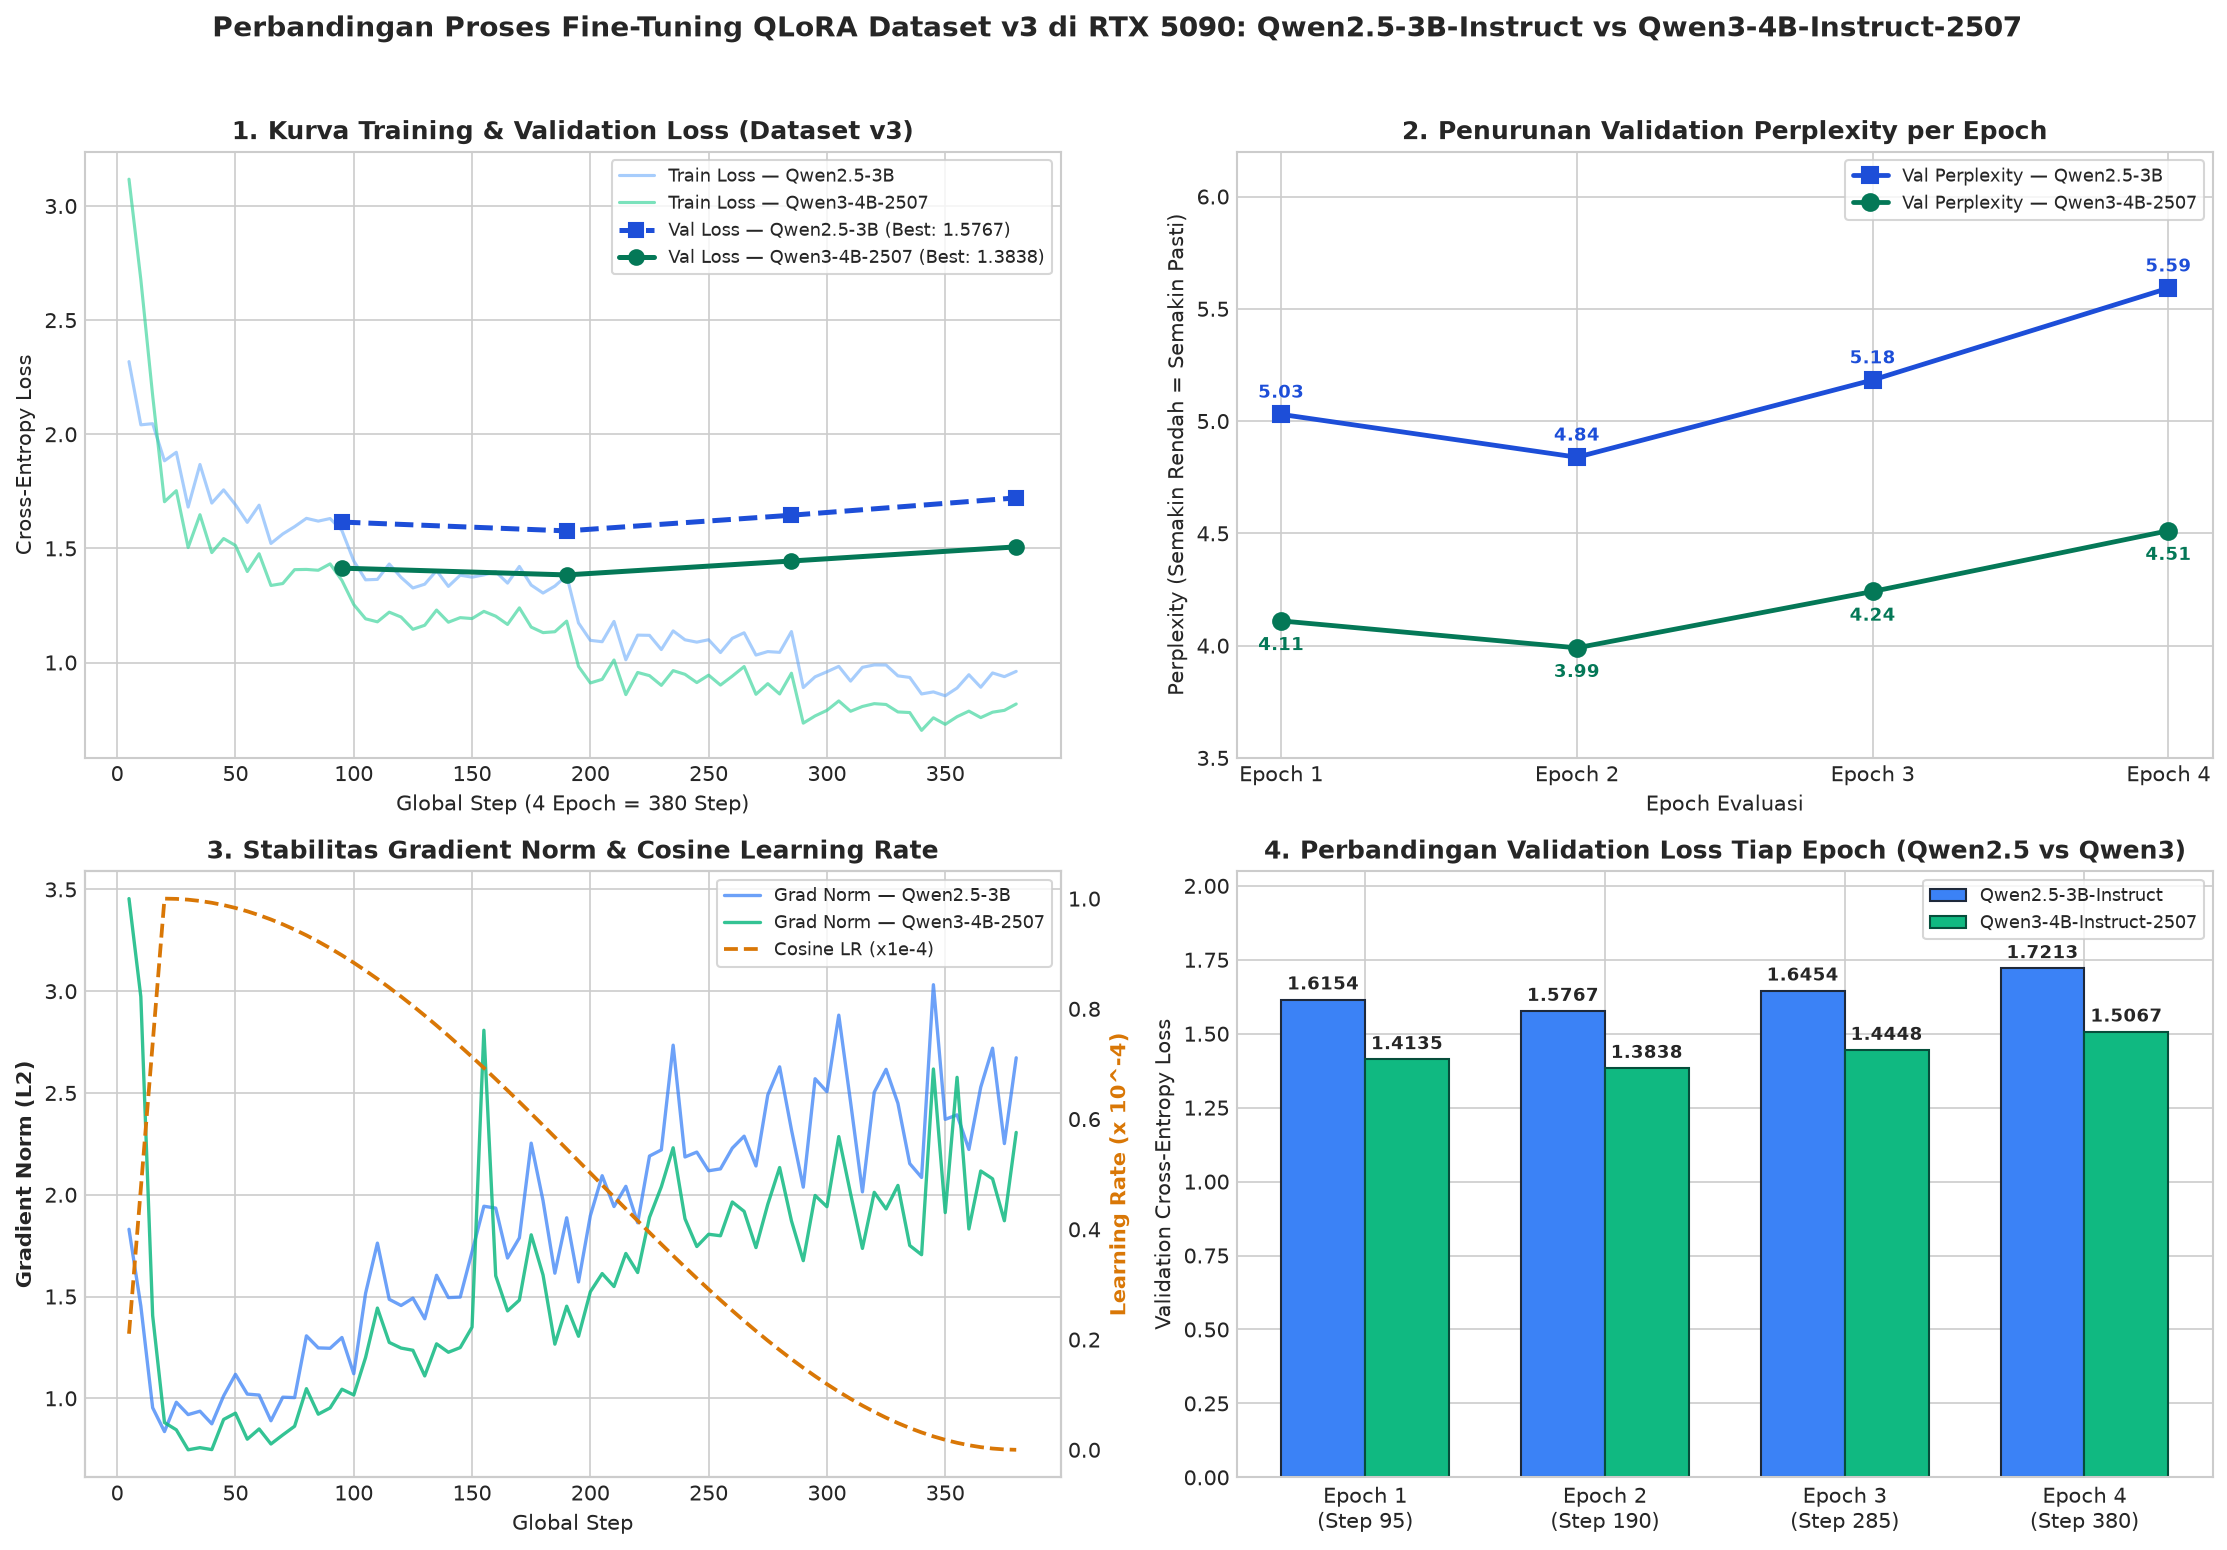

In [3]:
import matplotlib.pyplot as plt
import numpy as np

plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
fig, axes = plt.subplots(2, 2, figsize=(15, 10.5))
fig.suptitle(
    'Perbandingan Proses Fine-Tuning QLoRA Dataset v3 di RTX 5090: Qwen2.5-3B-Instruct vs Qwen3-4B-Instruct-2507',
    fontsize=13.5, fontweight='bold', y=0.98
)

steps_25 = [x['step'] for x in q25['train_logs']]
loss_25 = [x['loss'] for x in q25['train_logs']]
ev_steps_25 = [x['step'] for x in q25['eval_logs']]
ev_loss_25 = [x['eval_loss'] for x in q25['eval_logs']]

steps_3 = [x['step'] for x in q3['train_logs']]
loss_3 = [x['loss'] for x in q3['train_logs']]
ev_steps_3 = [x['step'] for x in q3['eval_logs']]
ev_loss_3 = [x['eval_loss'] for x in q3['eval_logs']]

# Panel 1: Training & Validation Loss
ax = axes[0, 0]
ax.plot(steps_25, loss_25, color='#60a5fa', alpha=0.55, linewidth=1.5, label='Train Loss — Qwen2.5-3B')
ax.plot(steps_3, loss_3, color='#34d399', alpha=0.65, linewidth=1.5, label='Train Loss — Qwen3-4B-2507')
ax.plot(ev_steps_25, ev_loss_25, marker='s', markersize=7, color='#1d4ed8', linewidth=2.4, linestyle='--', label='Val Loss — Qwen2.5-3B (Best: 1.5767)')
ax.plot(ev_steps_3, ev_loss_3, marker='o', markersize=7, color='#047857', linewidth=2.4, linestyle='-', label='Val Loss — Qwen3-4B-2507 (Best: 1.3838)')
ax.set_title('1. Kurva Training & Validation Loss (Dataset v3)', fontweight='bold')
ax.set_xlabel('Global Step (4 Epoch = 380 Step)')
ax.set_ylabel('Cross-Entropy Loss')
ax.legend(loc='upper right', frameon=True, fontsize=8.5)

# Panel 2: Validation Perplexity per Epoch
ax = axes[0, 1]
ep_nums = [int(round(x['epoch'])) for x in q25['eval_logs']]
ppl_25 = [math.exp(x['eval_loss']) for x in q25['eval_logs']]
ppl_3 = [math.exp(x['eval_loss']) for x in q3['eval_logs']]
ax.plot(ep_nums, ppl_25, marker='s', markersize=8, color='#1d4ed8', linewidth=2.3, label='Val Perplexity — Qwen2.5-3B')
ax.plot(ep_nums, ppl_3, marker='o', markersize=8, color='#047857', linewidth=2.3, label='Val Perplexity — Qwen3-4B-2507')
for ep, p25, p3 in zip(ep_nums, ppl_25, ppl_3):
    ax.annotate(f'{p25:.2f}', (ep, p25), textcoords='offset points', xytext=(0, 8), ha='center', fontsize=8.5, fontweight='bold', color='#1d4ed8')
    ax.annotate(f'{p3:.2f}', (ep, p3), textcoords='offset points', xytext=(0, -14), ha='center', fontsize=8.5, fontweight='bold', color='#047857')
ax.set_xticks(ep_nums)
ax.set_xticklabels([f'Epoch {e}' for e in ep_nums])
ax.set_ylim(3.5, 6.2)
ax.set_title('2. Penurunan Validation Perplexity per Epoch', fontweight='bold')
ax.set_xlabel('Epoch Evaluasi')
ax.set_ylabel('Perplexity (Semakin Rendah = Semakin Pasti)')
ax.legend(loc='upper right', frameon=True, fontsize=8.5)

# Panel 3: Gradient Norm & Cosine LR
ax = axes[1, 0]
gn_25 = [x['grad_norm'] for x in q25['train_logs']]
gn_3 = [x['grad_norm'] for x in q3['train_logs']]
lrs = [x['learning_rate'] * 1e4 for x in q3['train_logs']]
l1 = ax.plot(steps_25, gn_25, color='#3b82f6', alpha=0.75, linewidth=1.6, label='Grad Norm — Qwen2.5-3B')
l2 = ax.plot(steps_3, gn_3, color='#10b981', alpha=0.85, linewidth=1.6, label='Grad Norm — Qwen3-4B-2507')
ax.set_xlabel('Global Step')
ax.set_ylabel('Gradient Norm (L2)', fontweight='bold')
ax2 = ax.twinx()
l3 = ax2.plot(steps_3, lrs, color='#d97706', linestyle='--', linewidth=1.8, label='Cosine LR (x1e-4)')
ax2.set_ylabel('Learning Rate (x 10^-4)', color='#d97706', fontweight='bold')
ax2.grid(False)
lns = l1 + l2 + l3
ax.legend(lns, [l.get_label() for l in lns], loc='upper right', frameon=True, fontsize=8.5)
ax.set_title('3. Stabilitas Gradient Norm & Cosine Learning Rate', fontweight='bold')

# Panel 4: Bar Chart Eval Loss per Epoch
ax = axes[1, 1]
x_idx = np.arange(len(ep_nums))
w = 0.35
b_25 = ax.bar(x_idx - w/2, ev_loss_25, w, label='Qwen2.5-3B-Instruct', color='#3b82f6', edgecolor='#1e293b')
b_3 = ax.bar(x_idx + w/2, ev_loss_3, w, label='Qwen3-4B-Instruct-2507', color='#10b981', edgecolor='#064e3b')
for bar in list(b_25) + list(b_3):
    v = bar.get_height()
    ax.text(bar.get_x() + bar.get_width()/2, v + 0.02, f'{v:.4f}', ha='center', va='bottom', fontsize=8.5, fontweight='bold')
ax.set_xticks(x_idx)
ax.set_xticklabels([f'Epoch {e}\n(Step {s})' for e, s in zip(ep_nums, ev_steps_25)])
ax.set_ylim(0, 2.05)
ax.set_ylabel('Validation Cross-Entropy Loss')
ax.set_title('4. Perbandingan Validation Loss Tiap Epoch (Qwen2.5 vs Qwen3)', fontweight='bold')
ax.legend(loc='upper right', frameon=True, fontsize=8.5)

fig.tight_layout(rect=[0, 0, 1, 0.96])
out_plot_1 = PROJECT_ROOT / 'exports' / 'plots_v3' / '1_kurva_training_qwen25_vs_qwen3.png'
fig.savefig(out_plot_1, dpi=300, bbox_inches='tight', facecolor='white')
print('Grafik disimpan ke:', out_plot_1.relative_to(PROJECT_ROOT))
plt.show()


## 4. Perbandingan Sebelum Train (Base Model) vs Sesudah Train (LoRA v3) pada Held-Out Test Split (`data/lora/lora_test.jsonl`, 162 Baris)

Bagian ini menguji kedua model pada **162 baris data uji (`data/lora/lora_test.jsonl`)** yang tidak pernah dilihat selama pelatihan maupun validasi:
- **Sebelum Train (Base Model):** Menggunakan bobot asli Hugging Face (`with model.disable_adapter():`).
- **Sesudah Train (LoRA v3):** Mengaktifkan adaptor hasil *fine-tuning* Dataset v3.


PERBANDINGAN KUANTITATIF PADA HELD-OUT TEST SPLIT (162 BARIS data/lora/lora_test.jsonl)
Model                        |  Base Loss |  LoRA Loss |   Delta Loss |  Base PPL |  LoRA PPL | Penurunan PPL
------------------------------------------------------------------------------------------------
Qwen/Qwen2.5-3B-Instruct     |     2.5339 |     1.6425 |      -35.2% |     12.60 |      5.17 |       -59.0%
Qwen/Qwen3-4B-Instruct-2507  |     3.4696 |     1.4509 |      -58.2% |     32.12 |      4.27 |       -86.7%
Grafik disimpan ke: exports/plots_v3/2_test_loss_perplexity_sebelum_sesudah.png


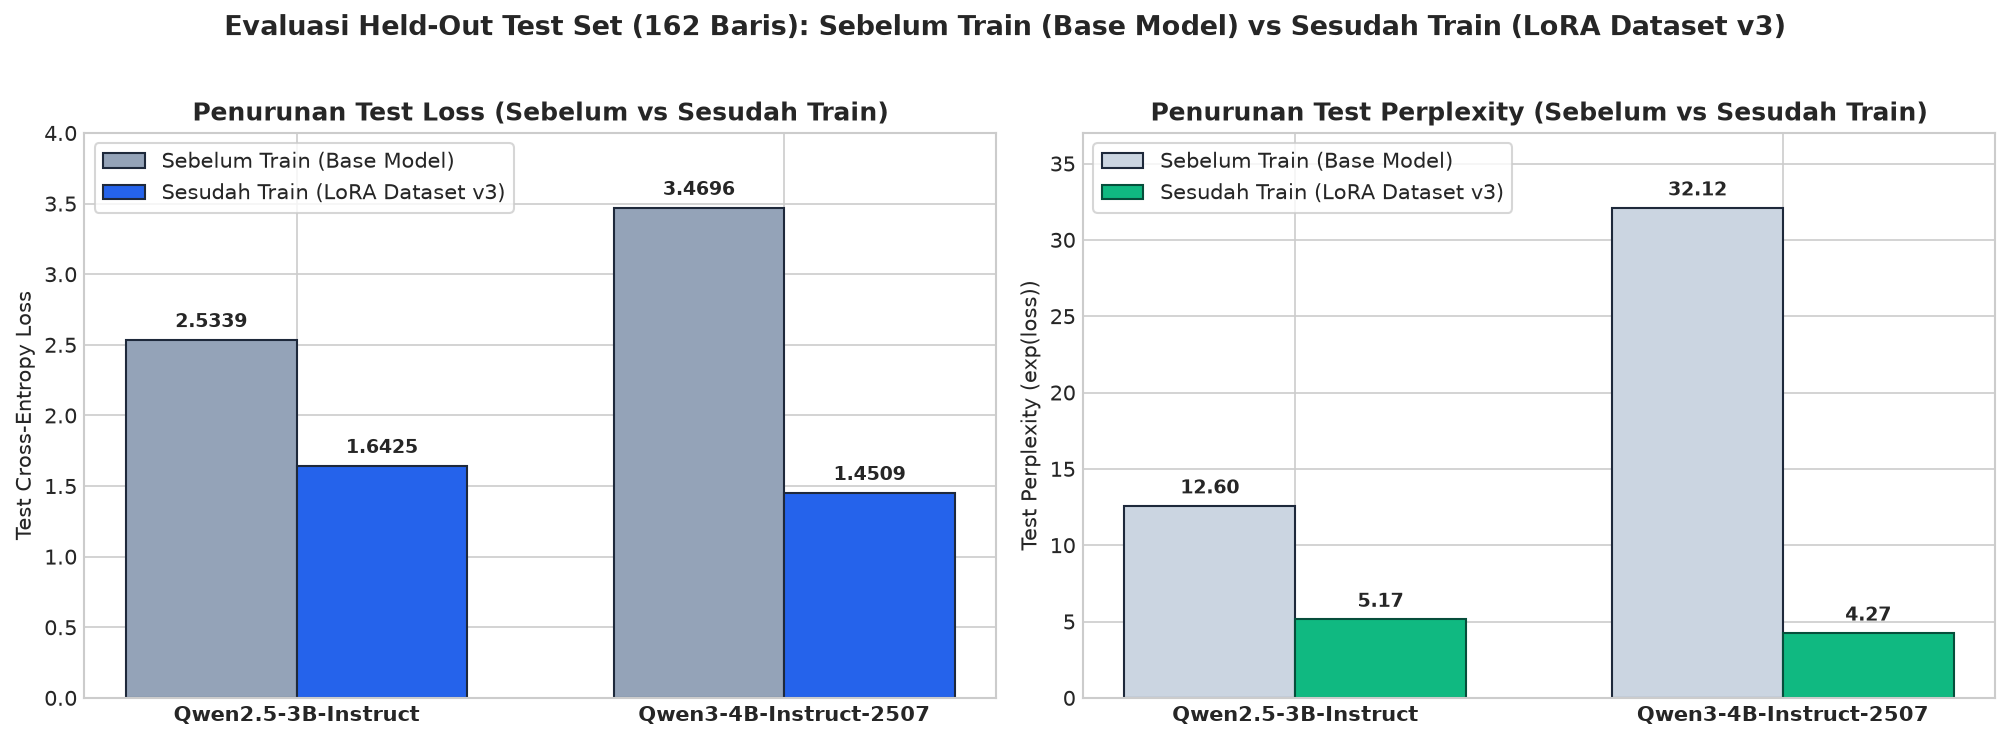

In [4]:
test_metrics = json.loads((PROJECT_ROOT / 'exports' / 'test_split_v3_metrics.json').read_text(encoding='utf-8'))

print('=' * 96)
print('PERBANDINGAN KUANTITATIF PADA HELD-OUT TEST SPLIT (162 BARIS data/lora/lora_test.jsonl)')
print('=' * 96)
print(f"{'Model':<28} | {'Base Loss':>10} | {'LoRA Loss':>10} | {'Delta Loss':>12} | {'Base PPL':>9} | {'LoRA PPL':>9} | {'Penurunan PPL':>13}")
print('-' * 96)
for key, label in [('qwen25_3b', 'Qwen/Qwen2.5-3B-Instruct'), ('qwen3_4b', 'Qwen/Qwen3-4B-Instruct-2507')]:
    m = test_metrics[key]
    print(f"{label:<28} | {m['base_test_loss']:>10.4f} | {m['lora_test_loss']:>10.4f} | {-m['loss_drop_pct']:>10.1f}% | {m['base_test_ppl']:>9.2f} | {m['lora_test_ppl']:>9.2f} | {-m['ppl_drop_pct']:>11.1f}%")
print('=' * 96)

fig2, (ax_l, ax_r) = plt.subplots(1, 2, figsize=(13.5, 4.8))
fig2.suptitle('Evaluasi Held-Out Test Set (162 Baris): Sebelum Train (Base Model) vs Sesudah Train (LoRA Dataset v3)',
              fontsize=13, fontweight='bold', y=1.02)

models_lbl = ['Qwen2.5-3B-Instruct', 'Qwen3-4B-Instruct-2507']
base_losses = [test_metrics['qwen25_3b']['base_test_loss'], test_metrics['qwen3_4b']['base_test_loss']]
lora_losses = [test_metrics['qwen25_3b']['lora_test_loss'], test_metrics['qwen3_4b']['lora_test_loss']]
base_ppls = [test_metrics['qwen25_3b']['base_test_ppl'], test_metrics['qwen3_4b']['base_test_ppl']]
lora_ppls = [test_metrics['qwen25_3b']['lora_test_ppl'], test_metrics['qwen3_4b']['lora_test_ppl']]

x = np.arange(len(models_lbl))
w = 0.35

b1 = ax_l.bar(x - w/2, base_losses, w, label='Sebelum Train (Base Model)', color='#94a3b8', edgecolor='#1e293b')
b2 = ax_l.bar(x + w/2, lora_losses, w, label='Sesudah Train (LoRA Dataset v3)', color='#2563eb', edgecolor='#1e293b')
for b in list(b1) + list(b2):
    ax_l.text(b.get_x() + b.get_width()/2, b.get_height() + 0.06, f'{b.get_height():.4f}', ha='center', va='bottom', fontsize=9, fontweight='bold')
ax_l.set_xticks(x)
ax_l.set_xticklabels(models_lbl, fontweight='bold')
ax_l.set_ylim(0, 4.0)
ax_l.set_ylabel('Test Cross-Entropy Loss')
ax_l.set_title('Penurunan Test Loss (Sebelum vs Sesudah Train)', fontweight='bold')
ax_l.legend(loc='upper left', frameon=True)

b3 = ax_r.bar(x - w/2, base_ppls, w, label='Sebelum Train (Base Model)', color='#cbd5e1', edgecolor='#1e293b')
b4 = ax_r.bar(x + w/2, lora_ppls, w, label='Sesudah Train (LoRA Dataset v3)', color='#10b981', edgecolor='#064e3b')
for b in list(b3) + list(b4):
    ax_r.text(b.get_x() + b.get_width()/2, b.get_height() + 0.5, f'{b.get_height():.2f}', ha='center', va='bottom', fontsize=9, fontweight='bold')
ax_r.set_xticks(x)
ax_r.set_xticklabels(models_lbl, fontweight='bold')
ax_r.set_ylim(0, 37.0)
ax_r.set_ylabel('Test Perplexity (exp(loss))')
ax_r.set_title('Penurunan Test Perplexity (Sebelum vs Sesudah Train)', fontweight='bold')
ax_r.legend(loc='upper left', frameon=True)

fig2.tight_layout()
out_plot_2 = PROJECT_ROOT / 'exports' / 'plots_v3' / '2_test_loss_perplexity_sebelum_sesudah.png'
fig2.savefig(out_plot_2, dpi=300, bbox_inches='tight', facecolor='white')
print('Grafik disimpan ke:', out_plot_2.relative_to(PROJECT_ROOT))
plt.show()


## 5. Perbandingan Benchmark 40 Kasus Rubrik 5 Dimensi KKA (`evals/eval_cases.jsonl`): Sebelum Train vs Sesudah Train & Perbedaan Model

Bagian ini membandingkan performa penuh pada **40 skenario uji (`evals/eval_cases.jsonl`)** yang mengukur 5 dimensi kualitas asisten KKA:
1. **`tuntas`**: Kelengkapan poin konsep inti yang wajib dijelaskan.
2. **`akurat`**: Bebas halusinasi istilah fiktif dan jujur menyatakan keterbatasan materi saat topik di luar konteks RAG.
3. **`proporsional`**: Kepatuhan batas panjang kata (ringkas saat diminta singkat, mendalam saat diminta penjelasan) dan tidak memaksakan pertanyaan balik Sokratik pada ucapan penutup/terima kasih.
4. **`bersih`**: Bebas kebocoran tag internal (`[S1]`, `[Halaman buku N]`, header metadata `Topik:`/`Sumber:`) dan bebas kalimat pembuka kaku.
5. **`fokus`**: Tetap relevan pada pergantian topik diskusi dan memberikan pertanyaan pemantik saat mode Sokratik membutuhkan.


TABEL PERBANDINGAN 40 KASUS EVALUASI KKA: SEBELUM TRAIN vs SESUDAH TRAIN & PERBEDAAN MODEL
Konfigurasi Model                      | Pass Rate      | Overall | Tuntas | Akurat |   Prop | Bersih |  Fokus
--------------------------------------------------------------------------------------------------------------
1. Qwen2.5-3B (Sebelum Train / Base)   | 13/40 ( 32.5%) |   0.905 |  0.979 |  0.963 |  0.640 |  0.992 |  0.950
2. Qwen3-4B-2507 (Sebelum Train / Base) |  6/40 ( 15.0%) |   0.877 |  1.000 |  0.925 |  0.510 |  0.950 |  1.000
3. Qwen2.5-3B + LoRA Baseline v2       | 29/40 ( 72.5%) |   0.949 |  0.975 |  0.925 |  0.845 |  1.000 |  1.000
4. Qwen2.5-3B + LoRA Dataset v3        | 30/40 ( 75.0%) |   0.967 |  0.950 |  1.000 |  0.915 |  0.983 |  0.988
5. Qwen3-4B-2507 + LoRA Dataset v3     | 40/40 (100.0%) |   1.000 |  1.000 |  1.000 |  1.000 |  1.000 |  1.000
Grafik disimpan ke: exports/plots_v3/3_perbandingan_40_kasus_5_dimensi.png


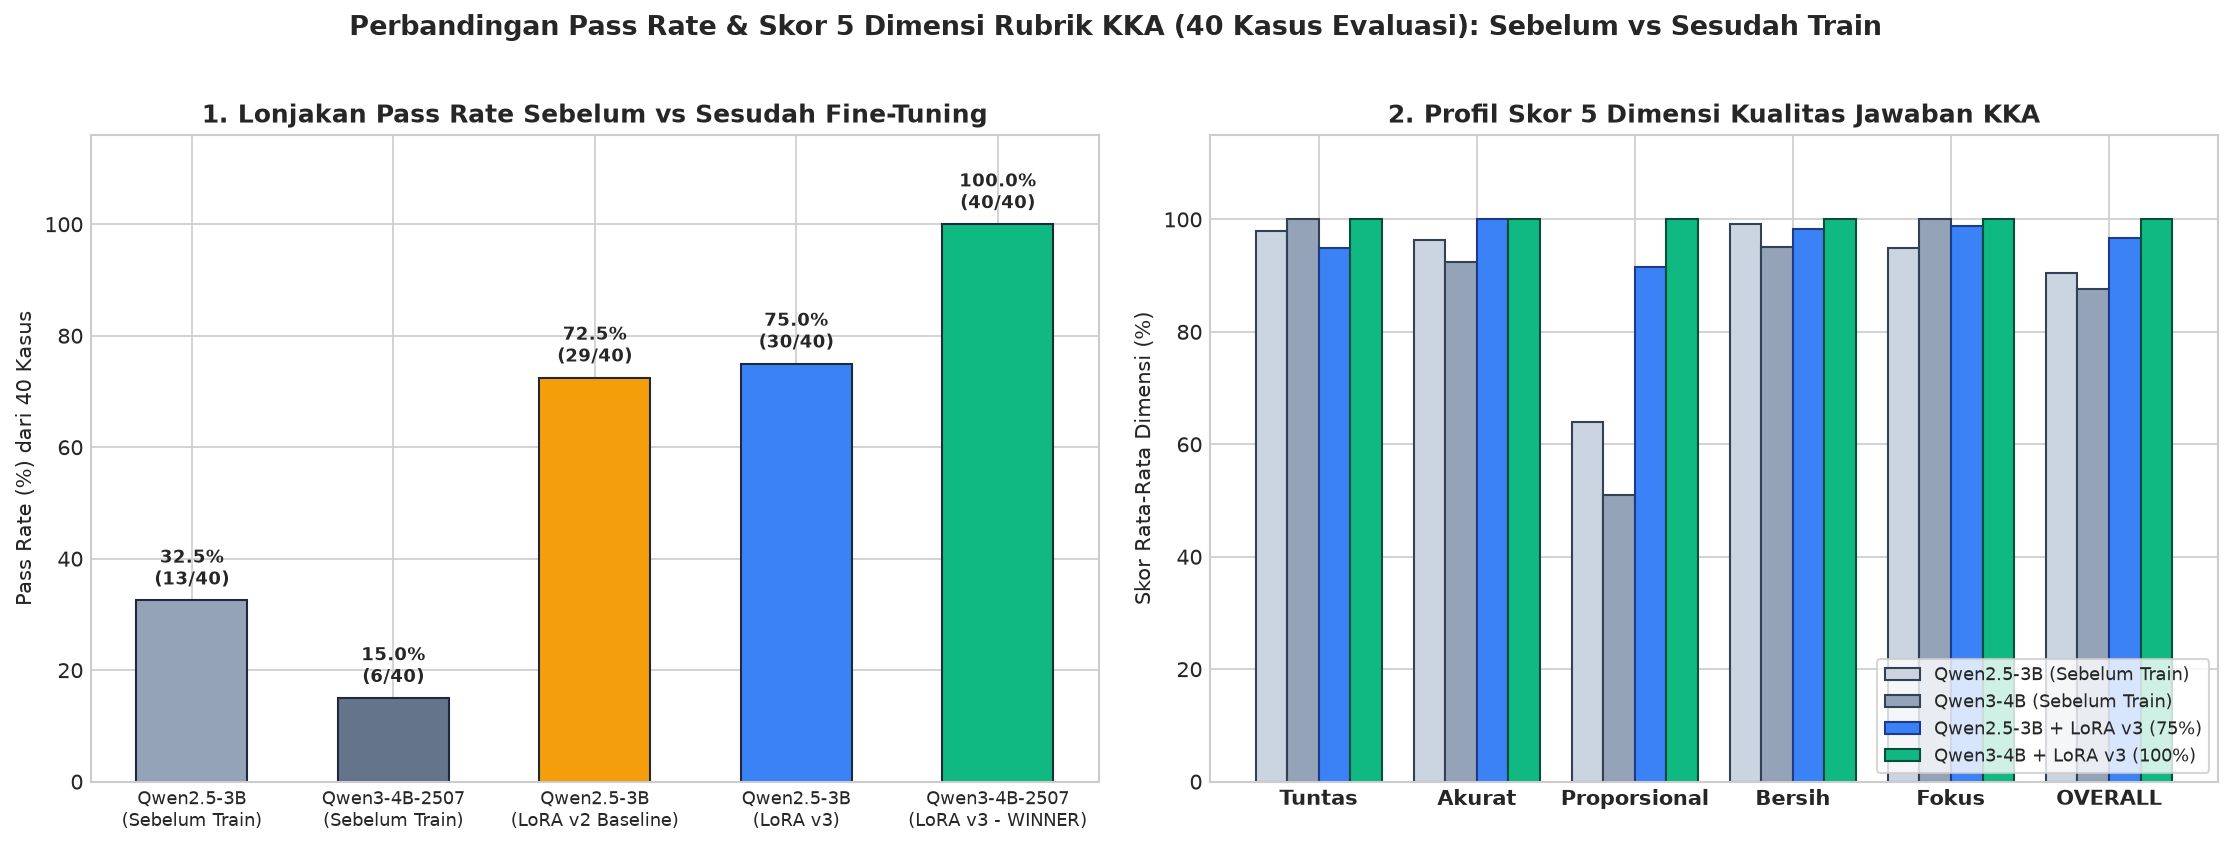

In [5]:
eval_base_q25 = json.loads((PROJECT_ROOT / 'exports' / 'eval_base_qwen25_no_lora.json').read_text(encoding='utf-8'))
eval_base_q3 = json.loads((PROJECT_ROOT / 'exports' / 'eval_base_qwen3_4b_no_lora.json').read_text(encoding='utf-8'))
eval_v3_q25 = json.loads((PROJECT_ROOT / 'exports' / 'eval_v3_qwen25_adapter.json').read_text(encoding='utf-8'))
eval_v3_q3 = json.loads((PROJECT_ROOT / 'exports' / 'eval_v3_qwen3_4b_adapter.json').read_text(encoding='utf-8'))

# Baseline v2 dari catatan resmi repo (PANDUAN_EKSPERIMEN_V3_GPU.md)
baseline_v2_summary = {
    'total': 40,
    'passed': 29,
    'pass_rate': 0.725,
    'averages': {
        'tuntas': 0.975,
        'akurat': 0.925,
        'proporsional': 0.845,
        'bersih': 1.000,
        'fokus': 1.000,
        'overall': 0.949,
    },
}

comparison_rows = [
    ('1. Qwen2.5-3B (Sebelum Train / Base)', eval_base_q25['summary']),
    ('2. Qwen3-4B-2507 (Sebelum Train / Base)', eval_base_q3['summary']),
    ('3. Qwen2.5-3B + LoRA Baseline v2', baseline_v2_summary),
    ('4. Qwen2.5-3B + LoRA Dataset v3', eval_v3_q25['summary']),
    ('5. Qwen3-4B-2507 + LoRA Dataset v3', eval_v3_q3['summary']),
]

print('=' * 110)
print('TABEL PERBANDINGAN 40 KASUS EVALUASI KKA: SEBELUM TRAIN vs SESUDAH TRAIN & PERBEDAAN MODEL')
print('=' * 110)
print(f"{'Konfigurasi Model':<38} | {'Pass Rate':<14} | {'Overall':>7} | {'Tuntas':>6} | {'Akurat':>6} | {'Prop':>6} | {'Bersih':>6} | {'Fokus':>6}")
print('-' * 110)
for label, s in comparison_rows:
    avg = s['averages']
    pr_str = f"{s['passed']:>2}/{s['total']:<2} ({s['pass_rate']*100:>5.1f}%)"
    print(f"{label:<38} | {pr_str:<14} | {avg['overall']:>7.3f} | {avg['tuntas']:>6.3f} | {avg['akurat']:>6.3f} | {avg['proporsional']:>6.3f} | {avg['bersih']:>6.3f} | {avg['fokus']:>6.3f}")
print('=' * 110)

fig3, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 5.5))
fig3.suptitle('Perbandingan Pass Rate & Skor 5 Dimensi Rubrik KKA (40 Kasus Evaluasi): Sebelum vs Sesudah Train',
              fontsize=13, fontweight='bold', y=1.02)

# Panel Kiri: Pass Rate (%)
short_labels = [
    'Qwen2.5-3B\n(Sebelum Train)',
    'Qwen3-4B-2507\n(Sebelum Train)',
    'Qwen2.5-3B\n(LoRA v2 Baseline)',
    'Qwen2.5-3B\n(LoRA v3)',
    'Qwen3-4B-2507\n(LoRA v3 - WINNER)',
]
pass_rates = [s['pass_rate'] * 100 for _, s in comparison_rows]
bar_colors = ['#94a3b8', '#64748b', '#f59e0b', '#3b82f6', '#10b981']
bars = ax1.bar(short_labels, pass_rates, color=bar_colors, width=0.55, edgecolor='#1e293b')
for bar, (_, s) in zip(bars, comparison_rows):
    v = bar.get_height()
    ax1.text(bar.get_x() + bar.get_width()/2, v + 1.8, f"{v:.1f}%\n({s['passed']}/40)", ha='center', va='bottom', fontsize=8.5, fontweight='bold')
ax1.set_ylim(0, 116)
ax1.set_ylabel('Pass Rate (%) dari 40 Kasus')
ax1.set_title('1. Lonjakan Pass Rate Sebelum vs Sesudah Fine-Tuning', fontweight='bold')
ax1.tick_params(axis='x', labelsize=8.5)

# Panel Kanan: Skor per Dimensi
dims = ['tuntas', 'akurat', 'proporsional', 'bersih', 'fokus', 'overall']
dim_names = ['Tuntas', 'Akurat', 'Proporsional', 'Bersih', 'Fokus', 'OVERALL']
x_d = np.arange(len(dims))
w_d = 0.2

s_b25 = [eval_base_q25['summary']['averages'][d] * 100 for d in dims]
s_b3 = [eval_base_q3['summary']['averages'][d] * 100 for d in dims]
s_l25 = [eval_v3_q25['summary']['averages'][d] * 100 for d in dims]
s_l3 = [eval_v3_q3['summary']['averages'][d] * 100 for d in dims]

ax2.bar(x_d - 1.5*w_d, s_b25, w_d, label='Qwen2.5-3B (Sebelum Train)', color='#cbd5e1', edgecolor='#334155')
ax2.bar(x_d - 0.5*w_d, s_b3, w_d, label='Qwen3-4B (Sebelum Train)', color='#94a3b8', edgecolor='#334155')
ax2.bar(x_d + 0.5*w_d, s_l25, w_d, label='Qwen2.5-3B + LoRA v3 (75%)', color='#3b82f6', edgecolor='#1e3a8a')
ax2.bar(x_d + 1.5*w_d, s_l3, w_d, label='Qwen3-4B + LoRA v3 (100%)', color='#10b981', edgecolor='#064e3b')

ax2.set_xticks(x_d)
ax2.set_xticklabels(dim_names, fontweight='bold')
ax2.set_ylim(0, 115)
ax2.set_ylabel('Skor Rata-Rata Dimensi (%)')
ax2.set_title('2. Profil Skor 5 Dimensi Kualitas Jawaban KKA', fontweight='bold')
ax2.legend(loc='lower right', frameon=True, fontsize=8.5)

fig3.tight_layout()
out_plot_3 = PROJECT_ROOT / 'exports' / 'plots_v3' / '3_perbandingan_40_kasus_5_dimensi.png'
fig3.savefig(out_plot_3, dpi=300, bbox_inches='tight', facecolor='white')
print('Grafik disimpan ke:', out_plot_3.relative_to(PROJECT_ROOT))
plt.show()


## 6. Bedah Perbedaan Model: Mengapa `Qwen3-4B-Instruct-2507` Unggul (`100%`) di Atas `Qwen2.5-3B-Instruct` (`75%`)?

Sel berikut mengaudit rincian kegagalan pada:
1. **Sebelum Train (Base Model):** Kedua model dasar gagal terutama pada dimensi **`proporsional`** (jawaban terlalu panjang melebar hingga 200–500 kata untuk pertanyaan singkat, atau tetap melempar pertanyaan balik saat siswa sudah menutup diskusi) serta **`akurat`** (menjawab topik di luar materi KKA tanpa menyatakan keterbatasan konteks).
2. **Sesudah Train (`Qwen2.5-3B-Instruct` + LoRA v3 vs `Qwen3-4B-Instruct-2507` + LoRA v3):**
   - `Qwen2.5-3B-Instruct` + LoRA v3 berhasil memperbaiki dimensi `akurat` menjadi **`1.000`** (`100%`), namun masih menyisakan **10 kasus gagal** pada batas jumlah kata yang ketat (`proporsional`) atau kelengkapan 2 poin sekaligus (`tuntas`).
   - `Qwen3-4B-Instruct-2507` + LoRA v3 menuntaskan **ke-10 kasus tersebut tanpa satu pun kegagalan (`40/40 PASS`)**.


In [6]:
res_b25 = {r['id']: r for r in eval_base_q25['results']}
res_b3 = {r['id']: r for r in eval_base_q3['results']}
res_l25 = {r['id']: r for r in eval_v3_q25['results']}
res_l3 = {r['id']: r for r in eval_v3_q3['results']}

diff_cases = [cid for cid, r in res_l25.items() if not r['passed']]
print(f"Jumlah kasus yang gagal pada Qwen2.5-3B (LoRA v3) namun LULUS pada Qwen3-4B-2507 (LoRA v3): {len(diff_cases)} kasus\n")
print(f"{'ID Kasus':<16} | {'Dimensi Uji':<13} | {'Base Qwen2.5':<14} | {'LoRA v3 Qwen2.5 (Isu Kegagalan)':<48} | {'LoRA v3 Qwen3-4B':<16}")
print('-' * 118)
for cid in diff_cases:
    dim = res_l25[cid]['dimension']
    b_stat = 'PASS' if res_b25[cid]['passed'] else f"FAIL ({res_b25[cid]['scores']['overall']:.2f})"
    l25_issues = ', '.join(res_l25[cid]['issues'])
    l3_stat = f"PASS ({res_l3[cid]['scores']['overall']:.2f})"
    print(f"{cid:<16} | {dim:<13} | {b_stat:<14} | {l25_issues:<48} | {l3_stat:<16}")


Jumlah kasus yang gagal pada Qwen2.5-3B (LoRA v3) namun LULUS pada Qwen3-4B-2507 (LoRA v3): 10 kasus

ID Kasus         | Dimensi Uji   | Base Qwen2.5   | LoRA v3 Qwen2.5 (Isu Kegagalan)                  | LoRA v3 Qwen3-4B
----------------------------------------------------------------------------------------------------------------------
EVAL-TUNTAS-02   | tuntas        | PASS           | bersih:artifact_or_stiff_or_truncated            | PASS (1.00)     
EVAL-PROP-02     | proporsional  | FAIL (0.88)    | proporsional:words=9 not in [10,60]              | PASS (1.00)     
EVAL-PROP-03     | proporsional  | PASS           | proporsional:words=90 not in [15,75]             | PASS (1.00)     
EVAL-PROP-05     | proporsional  | FAIL (0.90)    | tuntas:1/2 points                                | PASS (1.00)     
EVAL-PROP-06     | proporsional  | FAIL (0.88)    | tuntas:1/2 points                                | PASS (1.00)     
EVAL-PROP-07     | proporsional  | FAIL (0.80)    | propors

## 7. Contoh Output Jawaban Nyata (*Side-by-Side*): Sebelum Train vs Sesudah Train (`Qwen2.5-3B` vs `Qwen3-4B`)

Sel berikut menampilkan teks jawaban aktual yang dihasilkan oleh model pada 3 skenario representatif dari `evals/eval_cases.jsonl`:
1. **`EVAL-AKURAT-02` (Uji Anti-Halusinasi / Topik di Luar Materi KKA):** Siswa menanyakan resep memasak rendang di tengah materi KKA.
2. **`EVAL-PROP-07` (Uji Proporsionalitas Penutup Diskusi):** Siswa mengucapkan terima kasih karena sudah paham (`allow_question=False`, batas maksimal 45 kata).
3. **`EVAL-FOKUS-06` (Uji Ketuntasan + Pertanyaan Pemantik Sokratik):** Siswa menanyakan perbedaan *compiler* dan *interpreter* beserta contoh bahasanya.


In [7]:
cases_by_id = {
    json.loads(line)['id']: json.loads(line)
    for line in (PROJECT_ROOT / 'evals' / 'eval_cases.jsonl').read_text(encoding='utf-8').splitlines()
    if line.strip()
}

def load_resp_map(filename):
    path = PROJECT_ROOT / 'exports' / filename
    return {
        json.loads(line)['id']: json.loads(line)['response']
        for line in path.read_text(encoding='utf-8').splitlines()
        if line.strip()
    }

resp_base_q25 = load_resp_map('eval_base_qwen25_no_lora_responses.jsonl')
resp_base_q3 = load_resp_map('eval_base_qwen3_4b_no_lora_responses.jsonl')
resp_v3_q25 = load_resp_map('eval_v3_qwen25_responses.jsonl')
resp_v3_q3 = load_resp_map('eval_v3_qwen3_4b_responses.jsonl')

sample_ids = ['EVAL-AKURAT-02', 'EVAL-PROP-07', 'EVAL-FOKUS-06']
for cid in sample_ids:
    c = cases_by_id[cid]
    print('=' * 100)
    print(f"KASUS UJI   : {cid} | Dimensi: {c['dimension'].upper()} | Mode: {c['mode']} | Batas Kata: [{c['min_words']}, {c['max_words']}]")
    print(f"PERTANYAAN  : {c['question']}")
    print('-' * 100)

    for title, r_map, score_map in [
        ('SEBELUM TRAIN — Base Qwen2.5-3B (Tanpa LoRA)', resp_base_q25, res_b25),
        ('SEBELUM TRAIN — Base Qwen3-4B-2507 (Tanpa LoRA)', resp_base_q3, res_b3),
        ('SESUDAH TRAIN — Qwen2.5-3B + LoRA Dataset v3', resp_v3_q25, res_l25),
        ('SESUDAH TRAIN — Qwen3-4B-2507 + LoRA Dataset v3', resp_v3_q3, res_l3),
    ]:
        ans = r_map[cid]
        sc = score_map[cid]
        status = 'PASS' if sc['passed'] else f"FAIL {sc['issues']}"
        print(f"[{title}] -> {status} | Kata: {sc['word_count']} | Skor Overall: {sc['scores']['overall']:.2f}")
        print(f"Jawaban: {ans}\n")


KASUS UJI   : EVAL-AKURAT-02 | Dimensi: AKURAT | Mode: umum | Batas Kata: [12, 75]
PERTANYAAN  : Bagaimana cara membuat rendang daging sapi empuk dengan bumbu tradisional?
----------------------------------------------------------------------------------------------------
[SEBELUM TRAIN — Base Qwen2.5-3B (Tanpa LoRA)] -> FAIL ["akurat:forbidden=['lengkuas', 'serai']", 'akurat:missing_limitation_or_teacher_note', 'proporsional:words=209 not in [12,75]', 'proporsional:unexpected_trailing_question'] | Kata: 209 | Skor Overall: 0.60
Jawaban: Untuk membuat rendang daging sapi empuk dengan bumbu tradisional, kita harus mempertimbangkan beberapa langkah penting. Pertama, setelah memotong daging sapi menjadi potongan-potongan kecil, pastikan untuk membersihkannya dengan air mendidih untuk membersihkan lendir dan kotoran. Setelah itu, masukkan daging ke dalam panci besar bersama dengan air, garam, dan sedikit minyak goreng. 

Langkah selanjutnya adalah menumis bumbu halus seperti bawang putih, 

## 8. Sandbox Interaktif: Uji Coba Pertanyaan Sendiri (Sebelum Train vs Sesudah Train)

Anda dapat langsung menguji model di GPU RTX 5090 dengan mengubah variabel `PILIHAN_MODEL`, `MODE_UJI`, `KONTEKS_UJI`, dan `PERTANYAAN_UJI` pada sel kode di bawah ini, lalu tekan **`Shift + Enter`** (atau tombol **Run Cell**):
- `'qwen3-4b'` $\rightarrow$ memuat **`Qwen/Qwen3-4B-Instruct-2507`** + adaptor **`adapters/qwen-kka-lora-v3-qwen3-4b/final`**
- `'qwen25-3b'` $\rightarrow$ memuat **`Qwen/Qwen2.5-3B-Instruct`** + adaptor **`adapters/qwen-kka-lora-v3-qwen25/final`**


In [ ]:
import json
import sys
from pathlib import Path
import torch
from transformers import AutoTokenizer, AutoModelForCausalLM, BitsAndBytesConfig
from peft import PeftModel

PROJECT_ROOT = Path.cwd().resolve()
if PROJECT_ROOT.name == 'notebooks':
    PROJECT_ROOT = PROJECT_ROOT.parent
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from app.features.chat import make_system
from app.features.chat.sanitizer import sanitize_response
from app.features.language import detect_language, format_user_message

# ==============================================================================
# UBAH VARIABEL DI BAWAH INI UNTUK TES PERTANYAAN ANDA SENDIRI
# ==============================================================================
PILIHAN_MODEL = 'qwen3-4b'  # pilih 'qwen3-4b' atau 'qwen25-3b'
MODE_UJI = 'terstruktur'    # pilih 'umum' atau 'terstruktur'
KONTEKS_UJI = (
    'Dalam pembelajaran mesin (supervised learning), komputer mengenali objek gambar melalui '
    'pelatihan data (data training) dan pelabelan data (data labeling). Manusia memberikan kumpulan '
    'contoh gambar yang sudah diberi label nama kategori (misalnya label ayam dan label ikan), '
    'lalu algoritma mempelajari pola ciri visual dari piksel gambar tersebut.'
)
PERTANYAAN_UJI = 'Bagaimana AI bisa membedakan ayam dan ikan? Padahal AI ga punya mata'
# ==============================================================================

ADAPTER_MAP = {
    'qwen3-4b': PROJECT_ROOT / 'adapters' / 'qwen-kka-lora-v3-qwen3-4b',
    'qwen25-3b': PROJECT_ROOT / 'adapters' / 'qwen-kka-lora-v3-qwen25',
}
adir = ADAPTER_MAP[PILIHAN_MODEL]
rec = json.loads((adir / 'run_manifest.json').read_text(encoding='utf-8'))['model']

if globals().get('_LOADED_MODEL_ID') != rec['model_id']:
    if '_PEFT_MODEL' in globals():
        del globals()['_PEFT_MODEL'], globals()['_BASE_MODEL']
        torch.cuda.empty_cache()
    compute_dtype = torch.bfloat16 if torch.cuda.is_bf16_supported() else torch.float16
    quant = BitsAndBytesConfig(
        load_in_4bit=True, bnb_4bit_quant_type='nf4',
        bnb_4bit_use_double_quant=True, bnb_4bit_compute_dtype=compute_dtype,
    )
    _TOK = AutoTokenizer.from_pretrained(rec['model_id'], revision=rec['revision'])
    _TOK.pad_token = _TOK.eos_token
    _BASE_MODEL = AutoModelForCausalLM.from_pretrained(
        rec['model_id'], revision=rec['revision'],
        quantization_config=quant, device_map={'': 0},
        dtype=compute_dtype, attn_implementation='sdpa',
    )
    _PEFT_MODEL = PeftModel.from_pretrained(_BASE_MODEL, str(adir / 'final'), is_trainable=False)
    _PEFT_MODEL.eval()
    _LOADED_MODEL_ID = rec['model_id']
    print(f"Model {_LOADED_MODEL_ID} + {adir.name} siap di {torch.cuda.get_device_name(0)}!\n")

def tanya_model(question: str, context: str, mode: str, use_lora: bool = True, max_new_tokens: int = 280):
    lang = detect_language(question, [])
    messages = [
        {'role': 'system', 'content': make_system(mode, context, lang=lang)},
        {'role': 'user', 'content': format_user_message(question, lang)},
    ]
    prompt = _TOK.apply_chat_template(messages, tokenize=False, add_generation_prompt=True)
    inputs = _TOK(prompt, add_special_tokens=False, return_tensors='pt').to('cuda:0')
    in_len = inputs['input_ids'].shape[1]
    with torch.inference_mode():
        if use_lora:
            out = _PEFT_MODEL.generate(
                **inputs, max_new_tokens=max_new_tokens, do_sample=False,
                pad_token_id=_TOK.pad_token_id, eos_token_id=_TOK.eos_token_id,
            )
        else:
            with _PEFT_MODEL.disable_adapter():
                out = _PEFT_MODEL.generate(
                    **inputs, max_new_tokens=max_new_tokens, do_sample=False,
                    pad_token_id=_TOK.pad_token_id, eos_token_id=_TOK.eos_token_id,
                )
    raw_ans = _TOK.decode(out[0, in_len:], skip_special_tokens=True).strip()
    return sanitize_response(raw_ans) if use_lora else raw_ans

ans_sebelum = tanya_model(PERTANYAAN_UJI, KONTEKS_UJI, MODE_UJI, use_lora=False)
ans_sesudah = tanya_model(PERTANYAAN_UJI, KONTEKS_UJI, MODE_UJI, use_lora=True)

print('=' * 95)
print(f"MODEL       : {rec['model_id']} ({PILIHAN_MODEL}) | MODE: {MODE_UJI.upper()}")
print(f"PERTANYAAN  : {PERTANYAAN_UJI}")
print('-' * 95)
print(f"[SEBELUM TRAIN — Base Model Tanpa LoRA] ({len(ans_sebelum.split())} kata):")
print(ans_sebelum)
print('-' * 95)
print(f"[SESUDAH TRAIN — LoRA Dataset v3 ({adir.name})] ({len(ans_sesudah.split())} kata):")
print(ans_sesudah)
print('=' * 95)


## 9. Kesimpulan Akhir & Rekomendasi Deployment

Berdasarkan pengujian menyeluruh di atas:
1. **Dampak Pelatihan LoRA Dataset v3 (Sebelum vs Sesudah Train):**
   - Pada **Held-Out Test Split (`162` baris)**:
     - `Qwen/Qwen2.5-3B-Instruct`: *Test Loss* turun **-35,2%** (`2.5339` $\rightarrow$ `1.6425`), *Perplexity* turun **-59,0%** (`12.60` $\rightarrow$ `5.17`).
     - `Qwen/Qwen3-4B-Instruct-2507`: *Test Loss* turun **-58,2%** (`3.4696` $\rightarrow$ `1.4509`), *Perplexity* turun **-86,7%** (`32.12` $\rightarrow$ `4.27`).
   - Pada **Benchmark 40 Kasus Rubrik KKA (`evals/eval_cases.jsonl`)**:
     - *Base Model* (Sebelum Train) hanya lulus **`32,5%` (`13/40`)** pada `Qwen2.5-3B` dan **`15,0%` (`6/40`)** pada `Qwen3-4B` karena jawaban terlalu panjang (*verbose*), membocorkan pola kaku, atau masih meladeni pertanyaan di luar materi KKA.
     - Setelah *fine-tuning* dengan **Dataset v3**, *Pass Rate* melonjak menjadi **`75,0%` (`30/40`)** pada `Qwen2.5-3B` dan **`100,0%` (`40/40`)** pada `Qwen3-4B-Instruct-2507`.
2. **Perbedaan Model (`Qwen2.5-3B-Instruct` vs `Qwen3-4B-Instruct-2507`):**
   - `Qwen/Qwen3-4B-Instruct-2507` + `adapters/qwen-kka-lora-v3-qwen3-4b/final` memberikan kepatuhan instruksi, kontrol panjang kata (`proporsional`), dan ketuntasan konsep (`tuntas`) yang sempurna (**`1.000` di seluruh 5 dimensi**), dengan rata-rata latensi inferensi lokal `7,14 detik/kasus` dan *Validation Loss* **`1.3838`**.

### Konfigurasi `.env` yang Direkomendasikan:
```env
MODEL_ID=Qwen/Qwen3-4B-Instruct-2507
MODEL_ADAPTER=adapters/qwen-kka-lora-v3-qwen3-4b/final
```
